# Second Order Optimality Conditions

We test curvature of the **Lagrangian**, rather than the objective alone. Assume $f$, $g_i$ and $h_j$ are $C^2$ near the point being tested. Use $g_i\le0$, unrestricted equality multipliers, nonnegative inequality multipliers, and row Jacobians. The [KKT reference](KKT-Multipliers.ipynb) owns the active/strong/weak definitions; the [constraint-qualification reference](Constraint-Qualifications.ipynb) owns feasible paths and tangent versus linearized cones. This page develops the second-order proofs and computational tests used in Lecture 21.


In [1]:
# This code cell installs packages on Colab

import sys

if "google.colab" in sys.modules:
    !wget "https://raw.githubusercontent.com/ndcbe/optimization/main/notebooks/helper.py"
    import helper

    helper.easy_install()
else:
    sys.path.insert(0, "../")
    import helper
helper.set_plotting_style()

## Helpful Cones

### Linearized and critical directions

At a feasible KKT point $(\mathbf x^*,\mathbf u^*,\mathbf v^*)$, write $\mathcal A_I$ for active inequality indices, split into $\mathcal A_s$ (positive multiplier) and $\mathcal A_w$ (zero multiplier) **for the chosen KKT vector**. Combined active labels are tagged $(h,j)$ and $(g,i)$; equality 1 and inequality 1 are different constraints. With derivatives evaluated at the point,

$$C_1=\{\mathbf p:\mathbf{J}_h\mathbf p=\mathbf{0},\ J_{g,\mathcal A_I}\mathbf p\le\mathbf{0}\},$$

$$C_2=\{\mathbf p:\mathbf{J}_h\mathbf p=\mathbf{0},\ J_{g,\mathcal A_s}\mathbf p=\mathbf{0},\ J_{g,\mathcal A_w}\mathbf p\le\mathbf{0}\}.$$

At a KKT point, $C_2=C_1\cap\{\nabla f^T\mathbf p=\mathbf{0}\}$. Indeed stationarity gives $\nabla f^T\mathbf p=-\sum_{i\in\mathcal A_I}u_i^*\nabla g_i^T\mathbf p\ge0$. Each term is nonnegative; equality to zero forces $\nabla g_i^T\mathbf p=\mathbf{0}$ wherever $u_i^*>0$. Weakly active inequalities retain their one-sided restrictions. Biegler (2010), p. 79; Nocedal and Wright (2006), (12.53), p. 330.

Under LICQ, $C_1$ equals the **tangent cone**, including zero and arbitrary scales. Unit limiting directions are its unit section, as explained in the [qualification reference](Constraint-Qualifications.ipynb). Neither $C_1$ nor $C_2$ need be a linear subspace.


### Subspaces that bracket the critical cone

$$C_3=\ker\begin{bmatrix}\mathbf{J}_h\\J_{g,\mathcal A_I}\end{bmatrix},\qquad
C_4=\ker\begin{bmatrix}\mathbf{J}_h\\J_{g,\mathcal A_s}\end{bmatrix},\qquad C_3\subseteq C_2\subseteq C_4.$$

![Four sets with distinct direction restrictions](../../media/figures/cone-nesting-2d.png)

For $g_1=x_1\le0$, $g_2=x_2\le0$, $f=-x_1+x_2^2$, the origin has $(u_1,u_2)=(1,0)$. The panels then show a quadrant ($C_1$), a ray ($C_2$), just zero ($C_3$), and a line ($C_4$). Holding more independent rows at equality makes a smaller subspace.

$C_3$ is contained in $C_4$. Under LICQ the column counts are $n-\operatorname{rows}(\mathbf{A}_3)$ and $n-\operatorname{rows}(\mathbf{A}_4)$; without full row rank use $n-\operatorname{rank}(\mathbf{A}_i)$. A nonempty weak set adds independent rows under LICQ, but strict complementarity makes the two row sets identical. Their null spaces coincide; separately computed bases need not be numerically identical.


## Second Order Necessary Conditions

For $C^2$ data, a local minimum satisfying LICQ has unique KKT multipliers and obeys

$$\mathbf p^T \mathbf{W}\mathbf p\ge0\quad\text{for every }\mathbf p\in C_2,
\qquad \mathbf{W}=\nabla_{\mathbf{xx}}^2L(\mathbf x^*,\mathbf u^*,\mathbf v^*).$$

This is Biegler's Theorem 4.17, p. 80 (apply the errata), and Nocedal–Wright's Theorem 12.5, p. 332.

**Complete proof.** Fix $\mathbf p\in C_2$. LICQ and the feasible-path construction give $\mathbf z(t)=\mathbf x^*+t\mathbf p+o(t)$ with $h_j(\mathbf z(t))=0$ and each active inequality exactly $g_i(\mathbf z(t))=t\nabla g_i^T\mathbf p\le\mathbf{0}$. A strongly active inequality has zero directional derivative; weakly active and inactive constraints have zero multiplier. Thus $L(\mathbf z(t),\mathbf u^*,\mathbf v^*)=f(\mathbf z(t))$ exactly. Stationarity eliminates the linear Taylor term, so

$$f(\mathbf z(t))-f(\mathbf x^*)=\tfrac12t^2\mathbf p^T\mathbf{W}\mathbf p+o(t^2).$$

A negative quadratic coefficient dominates the remainder for sufficiently small positive $t$ and contradicts local minimality. This establishes the nonnegative curvature test.

![Negative feasible curvature contradicts a local minimum](../../media/figures/soc-necessary-proof.png)

The path correction is $o(t)$; the **second-order Taylor remainder** is $o(t^2)$. They are different quantities. The vanishing first derivative is what permits the $o(t)$ displacement correction to leave the quadratic coefficient unchanged.


## Second Order Sufficient Conditions

For $C^2$ data at a KKT point, suppose

$$\mathbf p^T\mathbf{W}\mathbf p>0\quad\text{for every nonzero }\mathbf p\in C_2.$$

Then $\mathbf x^*$ is a strict local minimum. LICQ is not required for this sufficient test. Biegler, Theorem 4.18, pp. 81–82; Nocedal–Wright, Theorem 12.6, pp. 333–334.

**Complete contradiction proof.** If strict local minimality fails, choose distinct feasible $\mathbf z^k\to\mathbf x^*$ with $f(\mathbf z^k)\le f(\mathbf x^*)$. Put $r_k=\|\mathbf z^k-\mathbf x^*\|>0$ and $\mathbf p_k=(\mathbf z^k-\mathbf x^*)/r_k$. Compactness of the unit sphere gives a subsequence $\mathbf p_k\to\mathbf p$ with $\|\mathbf p\|=1$. Constraint expansions give $\mathbf p\in C_1$ without any CQ. Dividing the objective difference by $r_k$ gives $\nabla f^T\mathbf p\le\mathbf{0}$; stationarity gives $\nabla f^T\mathbf p\ge\mathbf{0}$, hence $\mathbf p\in C_2$.

At every feasible point $L(\mathbf z^k,\mathbf u^*,\mathbf v^*)\le f(\mathbf z^k)$ because $\mathbf u^*\ge\mathbf{0}$, $g\le0$ and $h=0$. Also $L(\mathbf x^*,\mathbf u^*,\mathbf v^*)=f(\mathbf x^*)$. The stationary second-order expansion therefore yields

$$0\ge\frac{L(\mathbf z^k)-L(\mathbf x^*)}{r_k^2}
=\tfrac12\mathbf p_k^T\mathbf{W}\mathbf p_k+o(1)
\longrightarrow\tfrac12\mathbf p^T\mathbf{W}\mathbf p>0,$$

a contradiction. This proof includes directions approaching the critical cone, rather than assuming a direction limit for every original sequence.

![A putative lower-value sequence leads to positive critical curvature](../../media/figures/soc-sufficient-proof.png)

**Does SOSC imply SONC?** At a fixed multiplier vector, strict positivity implies nonnegativity on that same cone. But the necessary-condition theorem additionally assumes LICQ, whereas the sufficient-condition theorem does not. Do not transfer that hypothesis from one theorem to the other. In a degenerate problem different KKT vectors can give different Hessians and critical-cone descriptions; the fixed-vector sufficient test remains meaningful.

In Biegler's second proof case, all positive-multiplier terms contribute to the first-order Lagrangian/objective difference. Keeping only one chosen negative contribution supports an **inequality**, not an equality unless the other terms vanish. The argument above keeps the full sum and avoids that omission.


## Reduced Hessian

### A basis for a linear null space

For a full-row-rank $\mathbf{A}\in\mathbb R^{m\times n}$ with $m\le n$, a null-space basis $\mathbf{Z}\in\mathbb R^{n\times(n-m)}$ has full column rank and $\mathbf{AZ}=\mathbf{0}$. Every vector in $\ker \mathbf{A}$ is uniquely $\mathbf{Z}\mathbf q$. When $m=n$, the null space is $\{0\}$ and $\mathbf{Z}$ has zero columns; a curvature condition over its nonzero vectors is vacuous.

This is the row-oriented version of Biegler's Definition 4.19, p. 82. If rows are dependent, the correct dimension is $n-\operatorname{rank}\mathbf{A}$, obtained with a rank-revealing factorization or SVD. Pivoting detects the dependence; it does not make dependent rows independent. An arbitrary critical cone cannot be represented by $\mathbf{Z}\mathbf q$ with **unrestricted** $\mathbf q$: that image is a subspace.


### Complete QR construction and a small worked example

For independent rows, factor $\mathbf{A}^T=\mathbf{Q}[\mathbf{R};0]$, where $\mathbf{Q}=[\mathbf{Q}_R\ \mathbf{Q}_N]$ is $n\times n$ orthogonal and $\mathbf{R}$ is nonsingular $m\times m$ upper triangular. Since $\mathbf{Q}_R^T\mathbf{Q}_N=\mathbf{0}$,

$$\mathbf{AQ}_N=\mathbf{R}^T\mathbf{Q}_R^T\mathbf{Q}_N=\mathbf{0},$$

and $\mathbf{Q}_N$ has $n-m$ independent columns, so it spans the null space. An economic QR can omit this complement; request the complete factorization. Biegler (4.58), p. 82; Nocedal–Wright (12.74), p. 337.

For $\mathbf{A}=\left[\begin{smallmatrix}1&1&0\\0&1&1\end{smallmatrix}\right]$, choose

$$\mathbf{Q}_R=\begin{bmatrix}1/\sqrt2&-1/\sqrt6\\1/\sqrt2&1/\sqrt6\\0&2/\sqrt6\end{bmatrix},\quad
\mathbf{Z}=\frac{(-1,1,-1)^T}{\sqrt3},\quad
\mathbf{R}=\begin{bmatrix}\sqrt2&1/\sqrt2\\0&\sqrt{3/2}\end{bmatrix}.$$

Check $\mathbf{A}^T=\mathbf{Q}_R\mathbf{R}$, $\mathbf{AZ}=\mathbf{0}$ and $\mathbf{Z}^T\mathbf{Z}=1$. The two constraint planes intersect in the line spanned by $\mathbf{Z}$.

![Two independent constraint planes and their tangent line](../../media/figures/soc-nullspace-qr.png)

For numerical work use a stable library factorization, inspect the rank threshold, and check $\mathbf{AZ}$, the rank of $\mathbf{Z}$, and $\mathbf{Z}^T\mathbf{Z}$ when an orthonormal basis is intended. Loss of orthogonality does not by itself prove that a full-rank, exactly null basis fails to span the null space. The [Math-Primer D3 experiment](../6/Math-Primer.ipynb) illustrates orthogonality loss; its economic QR alone does not construct $\mathbf{Q}_N$. Watkins (2002), Sections 3.2–3.3, provides the reflector/rotator background.


### Reduced Hessian and basis invariance

For symmetric $\mathbf{W}$ and $\mathbf p=\mathbf{Z}\mathbf q$,

$$\mathbf p^T\mathbf{W}\mathbf p=\mathbf q^T(\mathbf{Z}^TWZ)\mathbf q.$$

Because $\mathbf{Z}$ is a full-rank basis for $\ker \mathbf{A}$, nonzero $\mathbf q$ and nonzero $\mathbf p$ correspond. Thus curvature is positive (semi)definite on this subspace exactly when the **reduced Hessian** $\mathbf{H}_R=\mathbf{Z}^TWZ$ is positive (semi)definite. A different basis $\widetilde{\mathbf{Z}}=\mathbf{Z}T$, with $T$ nonsingular, gives $\widetilde{\mathbf{H}}_R=T^T\mathbf{H}_RT$. Definiteness and inertia are invariant; eigenvalue magnitudes generally change. Orthonormal bases make eigenvalue scales easier to interpret.

![Indefinite full Hessian with positive feasible curvature](../../media/figures/reduced-hessian-saddle.png)

For $f=x_1^2-x_2^2$, $h=x_2=0$, the origin has $v=0$, $\mathbf{W}=\operatorname{diag}(2,-2)$ and $\mathbf{Z}=(1,0)^T$. Its reduced Hessian is 2, so the origin is a strict constrained minimum despite an indefinite full Hessian.

Let $\mathbf{Z}_3,\mathbf{Z}_4$ span $C_3,C_4$. Under the necessary theorem's hypotheses, $\mathbf{Z}_3^TWZ_3\succeq0$ is a **weaker necessary** test because it checks fewer directions. At a KKT point, $\mathbf{Z}_4^TWZ_4\succ0$ is a **stronger sufficient** test because it checks more directions than $C_2$ requires. Neither is a general equivalence to the exact cone test.

For example, on $x_1,x_2\ge0$, the function $f=\tfrac12(x_1^2+x_2^2+4x_1x_2)$ has a strict minimum at the origin with zero multipliers. Its critical cone is the nonnegative quadrant. The Hessian $\left[\begin{smallmatrix}1&2\\2&1\end{smallmatrix}\right]$ has eigenvalues 3 and −1, but $\mathbf p^T\mathbf{W}\mathbf p=p_1^2+p_2^2+4p_1p_2>0$ for every nonzero critical direction. The whole-space $C_4$ test fails although the exact SOSC holds. Conversely, the all-active null space can be zero and its necessary test vacuous even at a nonminimum. Strict complementarity makes $C_2=C_3=C_4$, so the subspace tests become exact. Biegler, pp. 82–83.


## Example

### Example 4.20: a positive one-dimensional reduced Hessian

Use the [canonical positive-domain log model](Local-Optimality.ipynb) with $g=4-x_1x_2\le0$. Biegler's Example 4.20 is on p. 83. Its solution is approximately $(1.7981,2.2245)$ with $u=0.5685>0$, so strict complementarity holds. The corrected Lagrangian Hessian is

$$\mathbf{W}=\begin{bmatrix}2+1/x_1^2&1-u\\1-u&3+1/x_2^2\end{bmatrix}
\approx\begin{bmatrix}2.3093&0.4315\\0.4315&3.2021\end{bmatrix}.$$

The gradient row is $\mathbf{J}_g=(-x_2,-x_1)$ and a unit tangent basis is approximately $(-0.6286,0.7777)^T$. The reduced Hessian is about 2.42736 using unrounded values; the errata's 2.4272 uses the rounded printed basis. The printed 1.0331 and Hessian (4.66) need the errata. With the displayed +9 objective, $f\approx-0.4944$; the book's −2.4944 is two lower, consistent with +7. The [existing source correction](Local-Optimality.ipynb) explains the constant without changing the derivatives or minimizer.


The Biegler errata corrects p. 83's Hessian and reduced-Hessian number. The native calculation below preserves the original rounded NumPy example, followed by the actual Pyomo solve and an analytic derivative/basis check. These are numerical evaluations of a supplied model, not a reason to reuse the uncorrected printed matrix.


### Calculation with numpy

In [2]:
import numpy as np

# Define the Hessian of the Lagrange function
hessian_L = np.array([[2.3093, 0.4315], [0.4315, 3.2021]])
print(hessian_L)

[[2.3093 0.4315]
 [0.4315 3.2021]]


In [3]:
# Define the gradient of the constraints
A = np.reshape(np.array([-2.2245, -1.7981]), (2, 1))

In [4]:
print(A)

[[-2.2245]
 [-1.7981]]


Calculate the complete QR factorization.

$$
\mathbf{A} = \mathbf{Q} \times \mathbf{R}
$$

In [5]:
# Calculate the COMPLETE QR factorization
Q, R = np.linalg.qr(A, mode="complete")

In [6]:
print(Q)

[[-0.77770385 -0.62863083]
 [-0.62863083  0.77770385]]


In [7]:
print(R)

[[2.86034331]
 [0.        ]]


In [8]:
print(Q @ R)

[[-2.2245]
 [-1.7981]]


The code's `A` stacks the single gradient as a **column**, so `A = J_g.T`. The second column of the complete $\mathbf{Q}$ lies in $\ker \mathbf{A}^T$, not $\ker \mathbf{A}$. Indeed $\mathbf{A}^T\mathbf{Q}_N=\mathbf{R}^T\mathbf{Q}_R^T\mathbf{Q}_N=\mathbf{0}$. Since $\mathbf{Q}_N$ has the right number of independent columns, it is a basis for the tangent line. Now evaluate $\mathbf{Q}_N^TWQ_N$.


In [9]:
# Calculate the reduced Hessian
print("Reduced Hessian w.r.t. null space of constraints:")
Q[:, 1].T @ hessian_L @ Q[:, 1]

Reduced Hessian w.r.t. null space of constraints:


np.float64(2.4273753426093774)

### Calculate with Pyomo

#### Define and solve the model

In [10]:
import pyomo.environ as pyo

m = pyo.ConcreteModel()

# Define variables
m.x1 = pyo.Var(initialize=1)
m.x2 = pyo.Var(initialize=1)

# Define constraints
# Note: changing this to an equality constraint
# changes the reduced_hessian
m.con1 = pyo.Constraint(expr=4 - m.x1 * m.x2 <= 0)

# Define objective
m.obj = pyo.Objective(
    expr=m.x1**2
    - 4 * m.x1
    + 1.5 * m.x2**2
    - 7 * m.x2
    + m.x1 * m.x2
    + 9
    - pyo.log(m.x1)
    - pyo.log(m.x2)
)

# Obtain dual solutions from first solve and send to warm start
m.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)

# Specify Ipopt as the solver and solve
opt = pyo.SolverFactory("ipopt")
results = opt.solve(m, tee=True)
assert pyo.check_optimal_termination(results), (
    f"Solve failed: status={results.solver.status}, "
    f"termination={results.solver.termination_condition}"
)

Ipopt 3.13.2: 

******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit http://projects.coin-or.org/Ipopt

This version of Ipopt was compiled from source code available at
    https://github.com/IDAES/Ipopt as part of the Institute for the Design of
    Advanced Energy Systems Process Systems Engineering Framework (IDAES PSE
    Framework) Copyright (c) 2018-2019. See https://github.com/IDAES/idaes-pse.

This version of Ipopt was compiled using HSL, a collection of Fortran codes
    for large-scale scientific computation.  All technical papers, sales and
    publicity material resulting from use of the HSL codes within IPOPT must
    contain the following acknowledgement:
        HSL, a collection of Fortran codes for large-scale scientific
        computation. See http://

#### Extract the dual variable for the constraint

In [11]:
m.dual[m.con1]

-0.5684977067847851

### Actual-point derivative and basis check

The model and solve above are unchanged. The following cell differentiates the actual Pyomo expressions and archives one shared basis-comparison figure. It records the point before the later experimental barrier calls solve the model again.


In [12]:
from pyomo.core.expr.calculus.derivatives import differentiate, Modes

variables = [m.x1, m.x2]
x_actual = np.array([pyo.value(v) for v in variables])
u_actual = -float(m.dual[m.con1])
g_expr = m.con1.body
gradient_actual = np.array(differentiate(m.obj.expr, wrt_list=variables))
jac_actual = np.array(differentiate(g_expr, wrt_list=variables)).reshape(1, 2)
lag_expr = m.obj.expr + u_actual * g_expr
lag_gradient = differentiate(lag_expr, wrt_list=variables, mode=Modes.reverse_symbolic)
W_actual = np.array([differentiate(e, wrt_list=variables) for e in lag_gradient])
Q_actual, _ = np.linalg.qr(jac_actual.T, mode="complete")
Z_actual = Q_actual[:, 1:]
bases = np.column_stack([Z_actual[:, 0], [1, -jac_actual[0, 0]/jac_actual[0, 1]],
                         [-jac_actual[0, 1]/jac_actual[0, 0], 1]])
reduced_values = np.einsum("ij,ik,kj->j", bases, W_actual, bases)
stationarity_actual = gradient_actual + jac_actual.T[:, 0] * u_actual
assert np.all(x_actual > 0) and u_actual > 0
assert np.linalg.norm(stationarity_actual, np.inf) < 1e-6
assert np.linalg.norm(jac_actual @ bases, np.inf) < 1e-12
assert np.all(reduced_values > 0)
print("Actual point:", x_actual, "canonical u:", u_actual)
print("Corrected Lagrangian Hessian:\n", W_actual)
print("Unit QR basis:", Z_actual[:, 0])
print("Reduced Hessians: unit QR, x1 parameter, x2 parameter:", reduced_values)
q_grid = np.linspace(-1, 1, 201)
x1_curve = np.linspace(x_actual[0] - .5, x_actual[0] + .5, 201)
soc_data = {"point": x_actual.tolist(), "objective": float(pyo.value(m.obj)),
            "u": u_actual, "J": jac_actual.tolist(), "W": W_actual.tolist(),
            "bases": bases.tolist(), "reduced_values": reduced_values.tolist(),
            "q": q_grid.tolist(), "quadratic_change": (.5*reduced_values[:,None]*q_grid[None,:]**2).tolist(),
            "curve_x1": x1_curve.tolist(), "curve_x2": (4/x1_curve).tolist()}
helper.save_results("soc-log-bases", soc_data, notebook="notebooks/7-dev/Second-Order.ipynb",
    source_cells=[("notebooks/7-dev/Second-Order.ipynb", "results:soc-log-model"),
                  ("notebooks/7-dev/Second-Order.ipynb", "results:soc-log-curvature")],
    description="Actual +9 log-model point, symbolic Lagrangian derivatives and three tangent parameter scales.",
    solver=str(opt), quiet=True)
results = soc_data


Actual point: [1.79811993 2.2245457 ] canonical u: 0.5684977067847851
Corrected Lagrangian Hessian:
 [[2.30928773 0.43150229]
 [0.43150229 3.20207721]]
Unit QR basis: [-0.62862724  0.77770676]
Reduced Hessians: unit QR, x1 parameter, x2 parameter: [2.42735934 6.14253567 4.01330651]


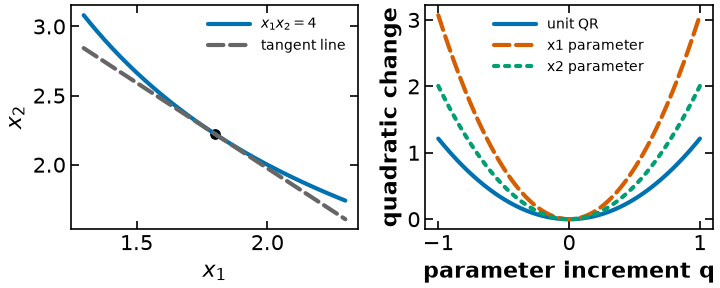

In [13]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.2))
point = np.asarray(results["point"])
jrow = np.asarray(results["J"])[0]
axes[0].plot(results["curve_x1"], results["curve_x2"], color="#0072B2", linestyle="-", label=r"$x_1x_2=4$")
tangent_x = np.asarray(results["curve_x1"])
axes[0].plot(tangent_x, point[1] - jrow[0]/jrow[1]*(tangent_x-point[0]),
             color="0.4", linestyle="--", label="tangent line")
axes[0].scatter(*point, color="black", marker="o", s=45)
axes[0].set(xlabel="$x_1$", ylabel="$x_2$")
axes[0].legend(fontsize=10)
styles = [("unit QR", "#0072B2", "-"), ("x1 parameter", "#D55E00", "--"),
          ("x2 parameter", "#009E73", ":")]
for values, (label, color, linestyle) in zip(results["quadratic_change"], styles):
    axes[1].plot(results["q"], values, color=color, linestyle=linestyle, label=label)
axes[1].set(xlabel="parameter increment q", ylabel="quadratic change")
axes[1].legend(fontsize=10)
fig.tight_layout()
helper.save_figure(fig, "soc-log-bases", quiet=True)


For this canonical upper inequality, the imported Pyomo suffix is negative and $u=-\texttt{m.dual[m.con1]}$ gives the nonnegative canonical multiplier. The analytic stationarity check above verifies the mapping at the actual point. See the [KKT suffix reference](KKT-Multipliers.ipynb) for other constraint orientations.

The original model comment about changing the inequality to an equality concerns the numerical barrier treatment. At the same point and matching multiplier, the **exact active-tangent** reduced Hessian is the same; changing a constraint's role does not by itself change that quadratic form.


#### Extract the reduced Hessian

In [14]:
# Warning: this Pyomo feature is experimental

from pyomo.contrib.interior_point.inverse_reduced_hessian import (
    inv_reduced_hessian_barrier,
)

# https://github.com/Pyomo/pyomo/blob/main/pyomo/contrib/interior_point/inverse_reduced_hessian.py

Compute the reduced Hessian with respect to $x_1$

In [15]:
solve_result, inv_red_hes = inv_reduced_hessian_barrier(
    m,
    independent_variables=[m.x1],  # Warning: these variables cannot be at their bounds
    tee=True,
)

print("\nReduced Hessian w.r.t. x1:")
print(np.linalg.inv(inv_red_hes))

Ipopt 3.13.2: bound_relax_factor=0
honor_original_bounds=no


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit http://projects.coin-or.org/Ipopt

This version of Ipopt was compiled from source code available at
    https://github.com/IDAES/Ipopt as part of the Institute for the Design of
    Advanced Energy Systems Process Systems Engineering Framework (IDAES PSE
    Framework) Copyright (c) 2018-2019. See https://github.com/IDAES/idaes-pse.

This version of Ipopt was compiled using HSL, a collection of Fortran codes
    for large-scale scientific computation.  All technical papers, sales and
    publicity material resulting from use of the HSL codes within IPOPT must
    contain the following acknowledgement:
        HSL, a collection of Fortran codes for large-sca


Reduced Hessian w.r.t. x1:
[[1.99699045]]


Compute the reduced Hessian with respect to $x_2$

In [16]:
solve_result, inv_red_hes = inv_reduced_hessian_barrier(
    m,
    independent_variables=[m.x2],  # Warning: these variables cannot be at their bounds
    tee=True,
)

print("\nReduced Hessian w.r.t. x2:")
print(np.linalg.inv(inv_red_hes))

Ipopt 3.13.2: bound_relax_factor=0
honor_original_bounds=no


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit http://projects.coin-or.org/Ipopt

This version of Ipopt was compiled from source code available at
    https://github.com/IDAES/Ipopt as part of the Institute for the Design of
    Advanced Energy Systems Process Systems Engineering Framework (IDAES PSE
    Framework) Copyright (c) 2018-2019. See https://github.com/IDAES/idaes-pse.

This version of Ipopt was compiled using HSL, a collection of Fortran codes
    for large-scale scientific computation.  All technical papers, sales and
    publicity material resulting from use of the HSL codes within IPOPT must
    contain the following acknowledgement:
        HSL, a collection of Fortran codes for large-sca


Reduced Hessian w.r.t. x2:
[[2.76904325]]


### Coordinate parameters are tangent bases, not coordinate-axis directions

At $x_1x_2=4$, the tangent basis for parameter $x_1$ is $Z_{x_1}=(1,-x_2/x_1)^T$, and for parameter $x_2$ it is $Z_{x_2}=(-x_1/x_2,1)^T$. Neither is the coordinate vector $(1,0)^T$ or $(0,1)^T$. Each equals a nonzero scalar multiple of the unit QR basis; consequently its reduced Hessian scales by the square of that scalar. Positive definiteness survives, while the three numerical values differ.

The [official experimental API documentation](https://pyomo.readthedocs.io/en/stable/_modules/pyomo/contrib/interior_point/inverse_reduced_hessian.html) and the installed implementation show that `inv_reduced_hessian_barrier` solves the model again, forms a **barrier-subproblem KKT matrix**, and extracts an inverse-Hessian block for selected independent variables. At a finite barrier parameter this is not an exact critical-cone certificate. Its selected variables must be away from their bounds. Check solve status, evaluate the actual active-point derivatives, and distinguish coordinate scaling from finite-barrier and roundoff effects when comparing outputs.
